In [ ]:
from pathlib import Path
from typing import Tuple
import numpy as np
from PIL import Image
from scipy.io import loadmat
from PIL import Image
import requests
from io import BytesIO
from  polyhood import Hood
import os

IMAGE_FILES_PER_FOLDER = 10000

# Loading data
print("Loading data")
hood_instance_gmsed = Hood(source="db_results/db_gmsed.zarr", multi=True)
hood_instance_gmsed.make_ann_index("KNN","MSED")

hood_instance_euc = Hood(source="db_results/db_full_img.zarr", multi=False)
hood_instance_euc.make_ann_index("KNN","euclidean")

print("Loaded data")

# Helper functions
def get_mf_image(index:int, size:Tuple[int,int]= None) -> Image.Image:

    folder_idx = index // IMAGE_FILES_PER_FOLDER
    url = f"https://similarity.cs.st-andrews.ac.uk/mirflickr/images/{folder_idx}/{index}.jpg"

    response = requests.get(url)

    img = Image.open(BytesIO(response.content))
    if size:

        assert len(size) ==  2, "Size tuple must have two elements."
        img = img.resize(size)

    return img

def make_mf_image_grid(img_indices: np.array, num_cols:int, num_rows:int, img_w:int, img_h:int) -> Image.Image:

    images = [get_mf_image(i)for i in img_indices]

    grid = Image.new("RGB", size=(num_cols* img_w, num_rows* img_h))

    for idx, img in enumerate(images):

        img = img.resize((img_w, img_h), Image.Resampling.BILINEAR)

        grid.paste(img, box=(idx% num_cols * img_w, idx // num_cols * img_h))

    return grid 

def load_id_of_image(hood_instance, index):
    db_ind = -1
    for i, m in enumerate(hood_instance.store.metadatas):
        if (eval(m)['path'] == "distribution_results/results/"+str(index)+"/"+str(index)+".jpg"):
            db_ind = i
    return db_ind

def load_imgs_from_id(elements):
    img_ids = [int(os.path.basename(eval(metadata)['path']).removesuffix('.jpg')) for id, embedding, metadata, distance in elements]
    return img_ids


def perform_search_comparison(id):
    # IMG_INDEX = load_id_of_image(hood_instance_gmsed, id)
    IMG_INDEX = id

    id, embedding, metadatas = hood_instance_gmsed.get([IMG_INDEX])[0]
    id_euc, embedding_euc, metadatas_euc = hood_instance_euc.get([IMG_INDEX])[0]

    print("Searching MSED")
    results_msed = hood_instance_gmsed.query([embedding], no_neigh=12)
    print("Searching Euclidean")
    results_euc = hood_instance_euc.query([embedding_euc], no_neigh=12)

    return [results_msed, results_euc]



Loading data
Data loaded from db_results/db_gmsed.zarr
Data loaded from db_results/db_full_img.zarr
Data loaded from db_results/db_gmsed.zarr
loaded data


In [ ]:
# Performing comparisons
img_ids = [374793, 1183, 293879, 629774, 693481,452895,561986,531139,768351,414490,20859,925526]
full_results = []
for index in tqdm(img_ids, total=len(img_ids), desc="Searching for nearest neighbours", unit=" Queries "):
    nearest_neigbours = perform_search_comparison(index)
    full_results.append(nearest_neigbours)

Comparing for: 925526
Searching MSED
Searching Euclidean
Searching iMSED


In [71]:
# Result demo parameters
GRID_X, GRID_Y, GRID_W, GRID_H = 4,3,200,200
results = full_results[0]

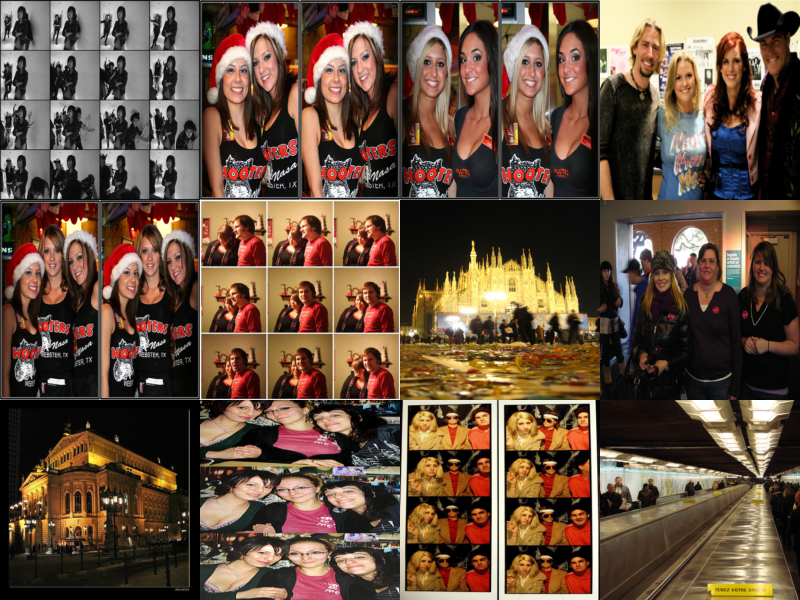

In [72]:
results_msed_imgs = load_imgs_from_id(results[0])
make_mf_image_grid(results_msed_imgs,GRID_X,GRID_Y,GRID_W,GRID_H)

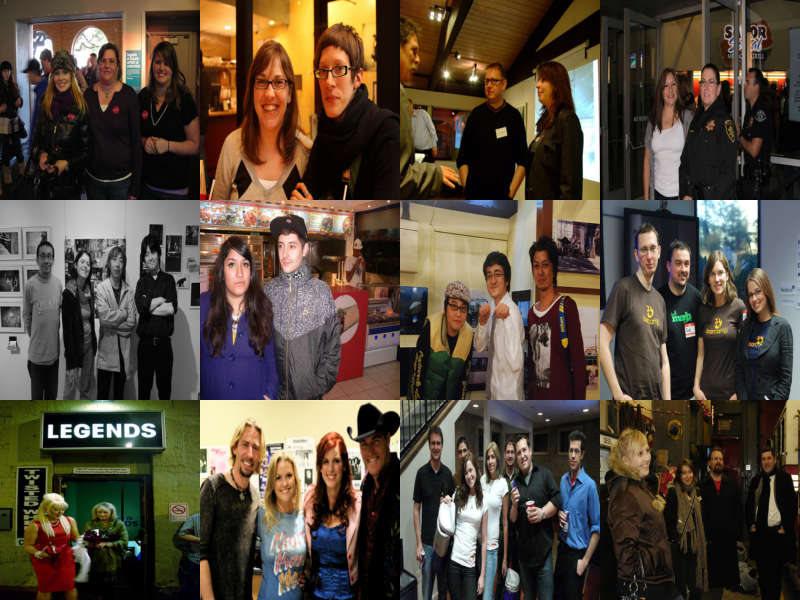

In [73]:
results_euc_imgs = load_imgs_from_id(results[1])
make_mf_image_grid(results_euc_imgs,GRID_X,GRID_Y,GRID_W,GRID_H)